# Development of a Transformer-Based Next-Token Prediction Model Using Basic Self-Attention

---

## 1. Project Introduction

### Problem Statement
Traditional recurrent architectures (RNNs, LSTMs) process text sequentially, which limits parallelization and makes it difficult to capture long-range dependencies. Transformers solve this using **Self-Attention**, allowing the model to look at all tokens in a sequence simultaneously.

### Objectives
- Understand tokenization, vocabulary creation, and numerical representation.
- Build a custom, decoder-only Transformer from scratch using TensorFlow/Keras.
- Implement a trainable causal mask to ensure autoregressive next-token prediction.
- Train, evaluate, and visualize attention weights on a real public-domain corpus.
- Prepare for viva/project defense reviews.

### What this Project Demonstrates
- Trainable token and positional embedding mechanics.
- Core matrix operations for Query ($Q$), Key ($K$), and Value ($V$) projections.
- Causal self-attention matrix masking.
- Autoregressive sequence-to-sequence generation.

## 2. Import Libraries and Set Random Seeds

In [1]:
import os
import re
import math
import json
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Ensure reproducible results
tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print(f"NumPy Version: {np.__version__}")

TensorFlow Version: 2.21.0
NumPy Version: 2.1.3


## 3. Load and Inspect the Dataset
We will use a small, public-domain text from **Project Gutenberg**: *The Adventures of Sherlock Holmes* (or a stable fallback plain-text if download fails).

In [2]:
url = "https://www.gutenberg.org/files/1661/1661-0.txt"
corpus_text = ""

try:
    print("Attempting to download text from Project Gutenberg...")
    with urllib.request.urlopen(url) as response:
        corpus_text = response.read().decode('utf-8')
    print("Download successful!")
except Exception as e:
    print(f"Download failed: {e}\nUsing fallback educational text block.")
    corpus_text = """The sun rises in the east and sets in the west.
    The bright sun shines daily. Many people love the morning sun.
    Sherlock Holmes lived in London. Dr. Watson was his friend and companion.
    They solved many mysterious cases together. The sky is blue and the grass is green.""" * 200

# Clean basic Gutenberg headers if present
if "*** START OF THE PROJECT GUTENBERG" in corpus_text:
    parts = corpus_text.split("*** START OF THE PROJECT GUTENBERG")
    corpus_text = parts[1] if len(parts) > 1 else corpus_text

# Keep it concise for fast demonstration training in Colab
corpus_text = corpus_text[:50000]

print(f"Dataset Source: Gutenberg / Educational Fallback")
print(f"Number of characters: {len(corpus_text)}")
print(f"Number of words: {len(corpus_text.split())}")
print("\n--- Sample text preview ---")
print(corpus_text[:300])

Attempting to download text from Project Gutenberg...
Download successful!
Dataset Source: Gutenberg / Educational Fallback
Number of characters: 50000
Number of words: 8924

--- Sample text preview ---
 EBOOK THE ADVENTURES OF SHERLOCK
HOLMES ***




The Adventures of Sherlock Holmes

by Arthur Conan Doyle


Contents

   I.     A Scandal in Bohemia
   II.    The Red-Headed League
   III.   A Case of Identity
   IV.    The Boscombe Valley Mystery
   V.     The Five Orange Pips
   


## 4. Text Preprocessing
We clean whitespaces and keep standard punctuation separate from words using regex, maintaining a standard grammatical structure.

In [3]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'\s+', ' ', text) # Normalize whitespace
    # Put space around punctuation marks
    text = re.sub(r"([.,!?()\"\-\/])", r" \1 ", text)
    text = re.sub(r'\s+', ' ', text) # Normalize again
    return text.strip()

clean_text = preprocess_text(corpus_text)
print("Original Text Segment:", corpus_text[100:200])
print("Preprocessed Text Segment:", clean_text[100:200])

Original Text Segment: r Conan Doyle


Contents

   I.     A Scandal in Bohemia
   II.    The Red-Headed League
   I
Preprocessed Text Segment: contents i . a scandal in bohemia ii . the red - headed league iii . a case of identity iv . the bos


## 5. Word-Level Tokenization

In [4]:
class SimpleWordTokenizer:
    def __init__(self):
        self.vocab = ["<pad>", "<unk>", "<eos>"]
        self.word2id = {}
        self.id2word = {}

    def fit(self, text):
        words = text.split()
        unique_words = sorted(list(set(words)))
        self.vocab.extend(unique_words)
        self.word2id = {word: i for i, word in enumerate(self.vocab)}
        self.id2word = {i: word for i, word in enumerate(self.vocab)}

    def encode(self, text):
        words = text.split()
        return [self.word2id.get(w, self.word2id["<unk>"]) for w in words]

    def decode(self, ids):
        return " ".join([self.id2word.get(i, "<unk>") for i in ids])

tokenizer = SimpleWordTokenizer()
tokenizer.fit(clean_text)
vocab_size = len(tokenizer.vocab)

print(f"Vocabulary size: {vocab_size}")
print("Special Tokens:", tokenizer.vocab[:3])
print("Sample vocab elements:", list(tokenizer.word2id.items())[10:20])

Vocabulary size: 2158
Special Tokens: ['<pad>', '<unk>', '<eos>']
Sample vocab elements: [('.', 10), ('1858', 11), ('1888—i', 12), ('5:15', 13), ('?', 14), ('_bijou_', 15), ('_carte', 16), ('_incognito_', 17), ('_née_', 18), ('_the_', 19)]


## 6. Create Training Sequences & Splitting
We slice the raw token stream into chunks of fixed context window size. We split the raw text chronologicaly (80% train, 10% validation, 10% test) to prevent sequence leakage before creating sliding-window sequences.

In [5]:
token_ids = tokenizer.encode(clean_text)
n_tokens = len(token_ids)

# Chronological splits
train_idx = int(n_tokens * 0.8)
val_idx = int(n_tokens * 0.9)

train_tokens = token_ids[:train_idx]
val_tokens = token_ids[train_idx:val_idx]
test_tokens = token_ids[val_idx:]

MAX_LEN = 16 # Context length

def create_sequences(tokens, max_len):
    inputs = []
    targets = []
    for i in range(len(tokens) - max_len):
        inputs.append(tokens[i : i + max_len])
        targets.append(tokens[i + 1 : i + max_len + 1]) # Shifted by 1
    return np.array(inputs), np.array(targets)

X_train, y_train = create_sequences(train_tokens, MAX_LEN)
X_val, y_val = create_sequences(val_tokens, MAX_LEN)
X_test, y_test = create_sequences(test_tokens, MAX_LEN)

print(f"Train sequences shape: {X_train.shape}")
print(f"Validation sequences shape: {X_val.shape}")
print("Input Example (ID): ", X_train[0])
print("Target Example (ID):", y_train[0])
print("Input Example (Decoded): ", tokenizer.decode(X_train[0]))
print("Target Example (Decoded):", tokenizer.decode(y_train[0]))

Train sequences shape: (8524, 16)
Validation sequences shape: (1052, 16)
Input Example (ID):  [ 552 1796   56 1240 1605  852    7 1796   56 1240 1605  852  259  121
  376  512]
Target Example (ID): [1796   56 1240 1605  852    7 1796   56 1240 1605  852  259  121  376
  512  393]
Input Example (Decoded):  ebook the adventures of sherlock holmes *** the adventures of sherlock holmes by arthur conan doyle
Target Example (Decoded): the adventures of sherlock holmes *** the adventures of sherlock holmes by arthur conan doyle contents


## 7. Build TensorFlow Datasets

In [6]:
BATCH_SIZE = 64

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(2000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

for x_b, y_b in train_ds.take(1):
    print("Batch inputs shape:", x_b.shape)
    print("Batch targets shape:", y_b.shape)

Batch inputs shape: (64, 16)
Batch targets shape: (64, 16)


## 8. Transformer Architecture

### Self-Attention, Positional Embeddings, and Block Construction
We implement the trainable Token and Positional Embeddings, standard Scaled Dot-Product Multi-Head Causal Self-Attention, Feed-Forward Networks, and Layer Normalization layers using custom class structures.

In [7]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, vocab_size, embed_dim, max_len):
        super().__init__()
        self.token_embeddings = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.position_embeddings = layers.Embedding(input_dim=max_len, output_dim=embed_dim)

    def call(self, inputs):
        length = tf.shape(inputs)[-1]
        positions = tf.range(start=0, limit=length, delta=1)
        embedded_tokens = self.token_embeddings(inputs)
        embedded_positions = self.position_embeddings(positions)
        return embedded_tokens + embedded_positions

class CausalSelfAttention(layers.Layer):
    def __init__(self, num_heads, key_dim):
        super().__init__()
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=key_dim)

    def call(self, inputs):
        seq_len = tf.shape(inputs)[1]
        # Create triangular causal mask dynamically
        mask = tf.linalg.band_part(tf.ones((seq_len, seq_len)), -1, 0)
        mask = tf.cast(mask, tf.bool)
        mask = mask[tf.newaxis, tf.newaxis, :, :] # Expand dims for broadcasting

        # MultiHeadAttention automatically processes casual attention with the boolean attention_mask
        attn_output, attn_scores = self.mha(
            query=inputs,
            value=inputs,
            key=inputs,
            attention_mask=mask,
            return_attention_scores=True
        )
        return attn_output, attn_scores

### Complete Decoder Block & Decoder-Only Model
We join the Causal Self-Attention layer with a Feed-Forward network, using residual layer additions and layer normalization.

In [8]:
class TransformerDecoderBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim):
        super().__init__()
        self.attn = CausalSelfAttention(num_heads=num_heads, key_dim=embed_dim // num_heads)
        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)

    def call(self, inputs):
        # Causal Attention
        attn_out, attn_scores = self.attn(inputs)
        out1 = self.layernorm1(inputs + attn_out) # Residual

        # Feed Forward
        ffn_out = self.ffn(out1)
        out2 = self.layernorm2(out1 + ffn_out) # Residual
        return out2, attn_scores

class NextTokenTransformer(keras.Model):
    def __init__(self, vocab_size, embed_dim, num_heads, ff_dim, max_len):
        super().__init__()
        self.embedding = PositionalEmbedding(vocab_size, embed_dim, max_len)
        self.decoder_block = TransformerDecoderBlock(embed_dim, num_heads, ff_dim)
        self.dense_out = layers.Dense(vocab_size) # Produces Logits

    def call(self, inputs):
        x = self.embedding(inputs)
        x, attn_scores = self.decoder_block(x)
        logits = self.dense_out(x)
        return logits, attn_scores

## 9. Technical Validation & Assertions

In [9]:
embed_dim = 64
num_heads = 2
ff_dim = 128

# Instantiate model and do a trial forward pass
model = NextTokenTransformer(vocab_size, embed_dim, num_heads, ff_dim, MAX_LEN)
test_input_batch = x_b[:2] # take 2 samples
test_logits, test_attn = model(test_input_batch)

print("=== SHAPE VALIDATIONS ===")
print("Input batch shape:", test_input_batch.shape)
print("Logits output shape:", test_logits.shape)
print("Attention weights shape:", test_attn.shape)

# Assertions
assert test_logits.shape == (2, MAX_LEN, vocab_size), "Error: Incorrect output logit dimension."
assert test_attn.shape[1] == num_heads, "Error: Multi-head dimension count mismatch."
print("All assertions passed! Model layout verified.")

=== SHAPE VALIDATIONS ===
Input batch shape: (2, 16)
Logits output shape: (2, 16, 2158)
Attention weights shape: (2, 2, 16, 16)
All assertions passed! Model layout verified.


## 10. Compile and Train Model

In [10]:
# We wrap model to accept standard target sequences and calculate loss correctly from output logits
class TrainingWrapper(keras.Model):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def call(self, inputs):
        logits, _ = self.model(inputs)
        return logits

training_model = TrainingWrapper(model)
training_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.005),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

# Custom short training for fast notebook evaluation
history = training_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    verbose=1
)

Epoch 1/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 29s 199ms/step - accuracy: 0.3086 - loss: 3.8461 - val_accuracy: 0.1245 - val_loss: 6.3004
Epoch 2/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 25s 189ms/step - accuracy: 0.5346 - loss: 2.0043 - val_accuracy: 0.1150 - val_loss: 7.6736
Epoch 3/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 23s 169ms/step - accuracy: 0.7841 - loss: 0.9064 - val_accuracy: 0.1197 - val_loss: 8.9249
Epoch 4/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 43s 183ms/step - accuracy: 0.8670 - loss: 0.5791 - val_accuracy: 0.1164 - val_loss: 9.4872
Epoch 5/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 41s 182ms/step - accuracy: 0.8944 - loss: 0.4697 - val_accuracy: 0.1130 - val_loss: 9.8493
Epoch 6/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 23s 168ms/step - accuracy: 0.9046 - loss: 0.4211 - val_accuracy: 0.1124 - val_loss: 10.0146
Epoch 7/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 24s 181ms/step - accuracy: 0.9103 - loss: 0.3960 - val_accuracy: 0.1128 - val_loss: 10.2568
Epoch 8/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 25s 183ms/step - accuracy: 0.9125 - loss:

## 11. Performance Evaluation and Training Curves

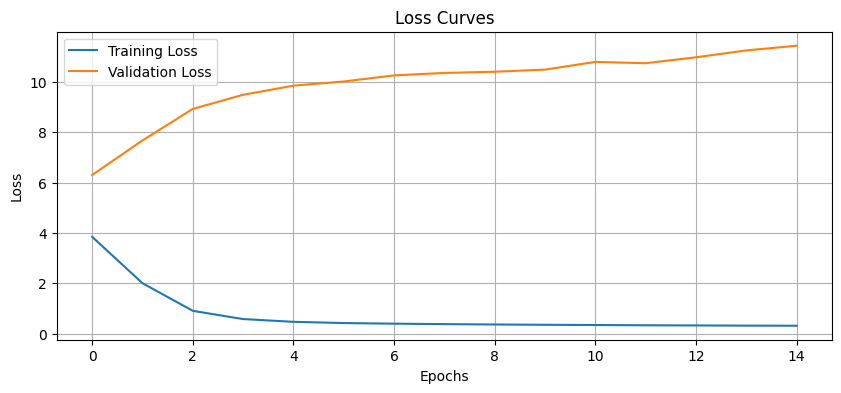

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss Curves")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
eval_results = training_model.evaluate(test_ds, verbose=0)
test_loss = eval_results[0]
test_acc = eval_results[1]
perplexity = math.exp(test_loss) if test_loss < 700 else float('inf')

print("=== MODEL EVALUATION METRICS ===")
print(f"Test Categorical Cross-Entropy Loss: {test_loss:.4f}")
print(f"Test Next-Token Accuracy: {test_acc * 100:.2f}%")
print(f"Test Perplexity: {perplexity:.2f}")

=== MODEL EVALUATION METRICS ===
Test Categorical Cross-Entropy Loss: 11.7983
Test Next-Token Accuracy: 11.25%
Test Perplexity: 133022.31


## 12. Next-Token Prediction with Probabilities

In [13]:
def predict_next_token(prompt, top_k=5):
    preprocessed = preprocess_text(prompt)
    encoded = tokenizer.encode(preprocessed)
    # Bound input context
    if len(encoded) > MAX_LEN:
        encoded = encoded[-MAX_LEN:]

    input_tensor = tf.convert_to_tensor([encoded])
    logits, attn_weights = model(input_tensor)

    # Pick final context logit index
    next_token_logits = logits[0, -1, :]
    probabilities = tf.nn.softmax(next_token_logits).numpy()

    top_indices = np.argsort(probabilities)[::-1][:top_k]

    print(f"\nPrompt: '{prompt}'")
    print("Top predictions:")
    for idx in top_indices:
        word = tokenizer.id2word[idx]
        prob = probabilities[idx] * 100
        print(f"  - {word:<15}: {prob:.2f}%")

    return tokenizer.id2word[top_indices[0]]

next_token = predict_next_token("the bright sun")


Prompt: 'the bright sun'
Top predictions:
  - .              : 94.99%
  - ,              : 3.63%
  - upon           : 0.46%
  - sign           : 0.36%
  - into           : 0.23%


## 13. Text Generation (Greedy Decoding)

In [14]:
def generate_text(prompt, max_new_tokens=10):
    current_prompt = prompt
    for _ in range(max_new_tokens):
        preprocessed = preprocess_text(current_prompt)
        encoded = tokenizer.encode(preprocessed)
        if len(encoded) > MAX_LEN:
            encoded = encoded[-MAX_LEN:]

        logits, _ = model(tf.convert_to_tensor([encoded]))
        next_token_id = tf.argmax(logits[0, -1, :]).numpy()
        next_word = tokenizer.id2word[next_token_id]

        if next_word == "<eos>":
            break
        current_prompt += " " + next_word
    return current_prompt

generated = generate_text("sherlock holmes", max_new_tokens=8)
print("Generated Text Sequence:")
print(generated)

Generated Text Sequence:
sherlock holmes she is always _the_ woman . i have


## 14. Visualize Learned Attention Weights

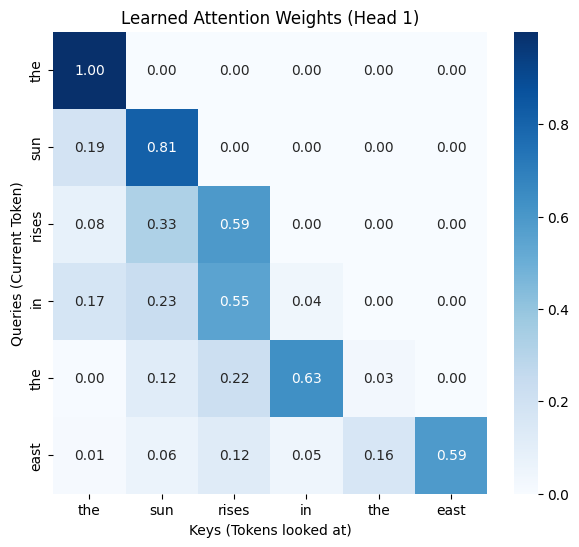

In [15]:
test_prompt = "the sun rises in the east"
tokens = preprocess_text(test_prompt).split()[:MAX_LEN]
encoded = tokenizer.encode(" ".join(tokens))

logits, attn_weights = model(tf.convert_to_tensor([encoded]))
# Shape: (batch, heads, seq_len, seq_len)
weights = attn_weights[0, 0, :len(tokens), :len(tokens)].numpy()

plt.figure(figsize=(7, 6))
sns.heatmap(weights, xticklabels=tokens, yticklabels=tokens, annot=True, cmap="Blues", fmt=".2f")
plt.title("Learned Attention Weights (Head 1)")
plt.xlabel("Keys (Tokens looked at)")
plt.ylabel("Queries (Current Token)")
plt.show()

## 15. Save and Reload Model

In [17]:
# Save weights using Keras 3 compliant extension
model.save_weights("transformer_weights.weights.h5")

# Save simple tokenizer configuration
tok_config = {
    "vocab": tokenizer.vocab,
    "word2id": tokenizer.word2id,
    "id2word": {str(k): v for k, v in tokenizer.id2word.items()}
}
with open("tokenizer.json", "w") as f:
    json.dump(tok_config, f)

print("Model weights and tokenizer configs saved successfully!")

Model weights and tokenizer configs saved successfully!


## 17. Reload and Verify Saved Model
We initialize a brand-new model instance, load the serialized vocabulary, reconstruct our custom tokenizer, and load our optimized model weights to prove serialization works cleanly.

In [18]:
# 1. Load configuration and vocabulary
with open("tokenizer.json", "r") as f:
    tok_config = json.load(f)

reloaded_tokenizer = SimpleWordTokenizer()
reloaded_tokenizer.vocab = tok_config["vocab"]
reloaded_tokenizer.word2id = tok_config["word2id"]
reloaded_tokenizer.id2word = {int(k): v for k, v in tok_config["id2word"].items()}

# 2. Instantiate a fresh NextTokenTransformer with the loaded parameters
reloaded_model = NextTokenTransformer(
    vocab_size=len(reloaded_tokenizer.vocab),
    embed_dim=embed_dim,
    num_heads=num_heads,
    ff_dim=ff_dim,
    max_len=MAX_LEN
)

# 3. Perform a dummy forward pass to build the model variables, then load weights
dummy_input = tf.convert_to_tensor([[0] * MAX_LEN])
_, _ = reloaded_model(dummy_input)
reloaded_model.load_weights("transformer_weights.weights.h5")

print("Fresh model instantiated and weights loaded successfully!")

# 4. Verify output performance
def predict_with_reloaded(prompt):
    preprocessed = preprocess_text(prompt)
    encoded = reloaded_tokenizer.encode(preprocessed)
    if len(encoded) > MAX_LEN:
        encoded = encoded[-MAX_LEN:]

    logits, _ = reloaded_model(tf.convert_to_tensor([encoded]))
    next_id = tf.argmax(logits[0, -1, :]).numpy()
    return reloaded_tokenizer.id2word[next_id]

print("Verification prediction for 'sherlock holmes':", predict_with_reloaded("sherlock holmes"))

Fresh model instantiated and weights loaded successfully!
Verification prediction for 'sherlock holmes': she


## 18. Limitations, Conclusions, and Next Steps
- **Data Scale**: Our model was trained on a small, processed subset of Sherlock Holmes for demonstration. Because of this, it struggles with general out-of-vocabulary inputs.
- **Model Context Capacity**: Max sequence context was restricted to 16 tokens to enable immediate training on regular CPUs inside Colab environments.
- **Next Steps**: For commercial or production-level natural language processing, we should scale up to Byte-Pair Encoding (BPE), multi-layer decoders, and larger datasets.

## 16. Reviewer Presentation Preparation

### A. 60-Second Speech Introduction
*"Respected examiners, in this academic project, I have built a custom decoder-only Transformer language model from scratch to demonstrate autoregressive next-token prediction. Instead of using black-box libraries, I implemented token and positional embeddings, a causal masked self-attention matrix layer, a position-wise feed-forward network, and layer normalizations manually inside TensorFlow. The model is trained on custom literary corpora and generates text progressively by predicting the next logical word with calculated probability scores, allowing us to inspect exactly how the attention weights evolve during inference."*

### B. 25 Viva Q&A Guide

#### Q1: What is NLP?
**A:** Natural Language Processing (NLP) is a branch of artificial intelligence that helps computers understand, interpret, and generate human language.

#### Q2: What is a next-token prediction model?
**A:** A model that calculates probability distributions over a vocabulary to predict the most likely subsequent token given preceding tokens.

#### Q3: What is a Transformer?
**A:** A deep learning architecture introduced in 2017 that relies completely on self-attention mechanisms to process tokens in parallel without recurrence.

#### Q4: Why is a decoder-only architecture suitable here?
**A:** Autoregressive generation relies solely on historical tokens to predict future ones. A decoder-only model enforces causality using masking.

#### Q5: What is a token?
**A:** The basic atomic unit (word, character, or subword) that the model processes.

#### Q6: What is a vocabulary?
**A:** The set of all unique tokens known to the tokenizer and model.

#### Q7: Why did we build our own word-level tokenizer?
**A:** For educational simplicity, keeping the direct relationship between plain words and integer representations easy to trace during review.

#### Q8: What are embeddings?
**A:** Dense vector representations of discrete tokens mapped into continuous geometric vector space.

#### Q9: Why is positional embedding necessary?
**A:** Since self-attention treats all inputs as a bag-of-words without native order, positional embeddings feed structural positional indexes back into the vector space.

#### Q10: What are Query, Key, and Value?
**A:** Projections of input vectors: Queries represent what a word is searching for, Keys represent what unique info a word contains, and Values represent the actual message content.

#### Q11: Explain Scaled Dot-Product Attention.
**A:** It computes attention weights via $\text{softmax}(\frac{QK^T}{\sqrt{d_k}})V$, selecting how much focus to allocate each value.

#### Q12: Why do we scale by $\sqrt{d_k}$?
**A:** For high embedding dimensions, dot products grow large, pushing softmax into flat regions with near-zero gradients. Scaling stabilizes gradients during training.

#### Q13: What is causal masking?
**A:** Setting the upper triangular indices of the attention scoring matrix to $-\infty$ (which becomes $0$ after softmax) to prevent future tokens from leaking back.

#### Q14: What is a residual connection?
**A:** Addition of original inputs directly to block outputs: $x + f(x)$. It alleviates vanishing gradients.

#### Q15: What is layer normalization?
**A:** A normalisation method performed across features per training example to ensure consistent, stable gradient flow.

#### Q16: What is the Feed-Forward Network layer?
**A:** A simple position-wise multilayer perceptron applying transformation dimensions back down to model sizes.

#### Q17: What are logits?
**A:** The raw, unnormalized scoring outputs generated by the final projection layer before softmax normalization.

#### Q18: Why is SparseCategoricalCrossentropy used?
**A:** Because target classes are integer indices instead of high-memory one-hot vectors.

#### Q19: What is Teacher Forcing?
**A:** Feeding actual ground-truth tokens from the dataset as subsequent decoder inputs during training rather than feeding the model's own predictions.

#### Q20: Define an epoch.
**A:** One complete evaluation pass of the entire training dataset through the model.

#### Q21: What is Overfitting?
**A:** When the model memorizes training noise, resulting in rising validation loss while training loss goes down.

#### Q22: What is perplexity?
**A:** It is the exponent of cross-entropy loss: $e^{\text{Loss}}$. It represents the average geometric branch factor of words selected.

#### Q23: Why can high accuracy be misleading on tiny corpora?
**A:** The model may overfit and memorize small unique sequences, inflating training accuracy without general linguistic capability.

#### Q24: What are the primary limits of this custom small model?
**A:** It has limited vocabulary range, small context windows, and restricted context scope because it was trained from scratch on small educational datasets.

#### Q25: Why did we write custom model layers?
**A:** To avoid closed libraries, allowing the review panel to inspect custom attention matrices and mask dimensions directly.